# Baseline Visualization — Rolling One-Step Protocol


Nội dung:
- So sánh Naive, Moving Average (1 → 52 - tuần), Seasonal Naive (SN-13/26/39/52 - tuần theo quý), Holt-Winters (Additive/Multiplicative)
- **Val2023**: chạy toàn bộ baseline và chọn model theo **RMSE thấp nhất**.
- **Val2024**: chỉ kiểm tra độ ổn định của model.
- **Test2025**: đánh giá.
- Metrics sử dụng: **RMSE, MAE, sMAPE**.
- Forecasting protocol: **rolling one-step-ahead**
- Phân tích mức độ ổn định của từng nhóm mô hình.
- Lựa chọn baseline phù hợp nhất dựa trên các tiêu chí đánh giá.



In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def find_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "outputs" / "baseline").is_dir():
            return path
    raise FileNotFoundError(
        "Could not find the project root directory containing 'outputs/baseline'."
    )


PROJECT_ROOT = find_root()
base = PROJECT_ROOT / "outputs" / "baseline"

print(f"Project root: {PROJECT_ROOT}")
print(f"Baseline data: {base}")

FileNotFoundError: Could not find the project root directory containing 'outputs/baseline'.

In [ ]:
val_2023 = pd.read_csv(base / "val_23_results.csv")
summary = pd.read_csv(base / "baseline_summary.csv")
prediction_check = pd.read_csv(base / "prediction_check_25.csv",parse_dates=["week_start"])

ma = [f"MA-{w}" for w in range(2, 53)]
sn = ["SN-13", "SN-26", "SN-39", "SN-52"]
hw = ["HW-add", "HW-mul"]


## 1. Lựa chọn baseline trên Validation 2023
Toàn bộ candidate được so sánh trên `Val2023`. Model có `RMSE thấp nhất` được chọn làm baseline chính thức
Tổng quan hiệu năng các baseline:
- Baseline 1: Naive
- Baseline 2: Moving Average (1–52 tuần)
- Baseline 3: Seasonal Naive (13, 26, 39 và 52 tuần)
- Baseline 4: Holt-Winters (Additive và Multiplicative)

In [ ]:
valid_23 = val_2023.dropna(subset=["RMSE"]).copy()
best_row = valid_23.sort_values("RMSE").iloc[0]
BEST_MODEL = best_row["Baseline"]

print("Selected baseline:", BEST_MODEL)
print(f"RMSE  : {best_row['RMSE']:.4f}")
print(f"MAE   : {best_row['MAE']:.4f}")
print(f"sMAPE : {best_row['sMAPE']:.4f}%")


Selected baseline: MA-32
RMSE  : 664.8961
MAE   : 529.1442
sMAPE : 15.7710%


**Nhận xét:** Trong toàn bộ các baseline candidate. mô hình `MA-32` (trung bình trượt cửa sổ 32 tuần, ~7.5 tháng) cho RMSE thấp nhất trên `Val2023`. sMAPE `~15.8%` nghĩa là sai số trung bình `khoảng 15–16%` so với giá trị thực - mức chấp nhận được cho một baseline đơn giản, phù hợp làm mốc so sánh cho các mô hình phức tạp hơn sau này.

## 2. Top 10 baseline models trên Val2023

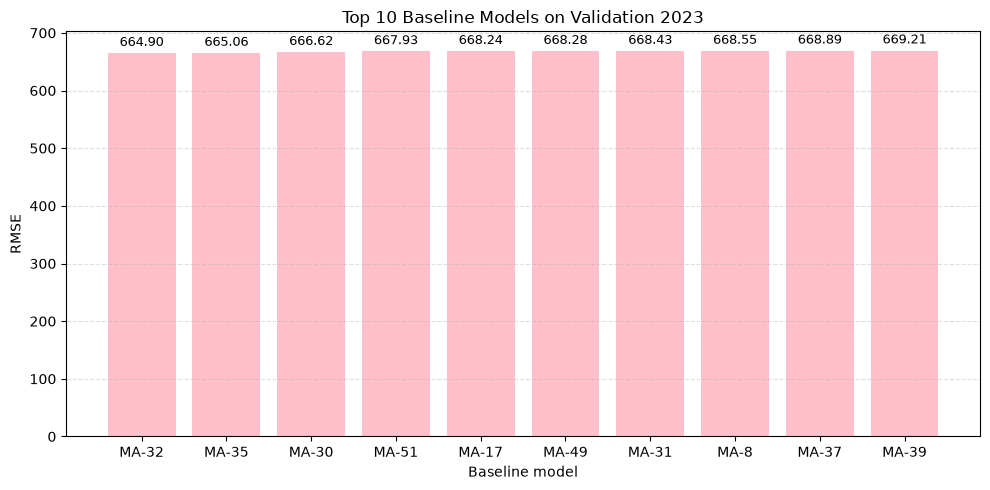

,Baseline,RMSE,MAE,sMAPE
32,MA-32,664.8961,529.1442,15.7710
35,MA-35,665.0579,530.0016,15.7950
30,MA-30,666.6232,529.9361,15.7920
51,MA-51,667.9294,540.5072,16.1118
17,MA-17,668.2397,532.7533,15.8633
49,MA-49,668.2822,537.6894,16.0255
31,MA-31,668.4336,532.7836,15.8764
8,MA-8,668.5462,528.8598,15.7305
37,MA-37,668.8950,531.8367,15.8584
39,MA-39,669.2121,529.0149,15.7707


In [ ]:
top10 = (valid_23.sort_values("RMSE").head(10))
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(top10["Baseline"], top10["RMSE"], color="pink")
ax.bar_label(bars, labels=[f"{value:.2f}" for value in top10["RMSE"]], padding=3,         fontsize=9)
ax.set_xlabel("Baseline model")
ax.set_ylabel("RMSE")
ax.set_title("Top 10 Baseline Models on Validation 2023")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

display(
    top10[["Baseline", "RMSE", "MAE", "sMAPE"]]
)


**Nhận xét:** Top 10 baseline trên `Val2023` đều thuộc nhóm `Moving Average` với RMSE dao động trong khoảng hẹp `664.9–669.9` (chênh lệch chưa đến 1%), cho thấy hiệu năng của MA khá "phẳng" quanh vùng cửa sổ 8–51 tuần chứ không có một cửa sổ nào vượt trội rõ rệt. Cả cửa sổ nhỏ (MA-8) lẫn cửa sổ lớn (MA-51) đều lọt vào top 10, gợi ý chuỗi doanh thu không có một chu kỳ mùa vụ chi phối rõ ràng mà MA có thể khai thác tốt hơn ở một độ dài cụ thể. Không có Naive, Seasonal Naive hay Holt-Winters nào lọt top 10 - các nhóm này yếu hơn hẳn MA trên `Val2023`.

Model có RMSE thấp nhất trên Val2023 được chọn làm baseline chính thức và được khóa cho các giai đoạn đánh giá tiếp theo.

## 3. Phân tích nhóm Moving Average trên Val2023

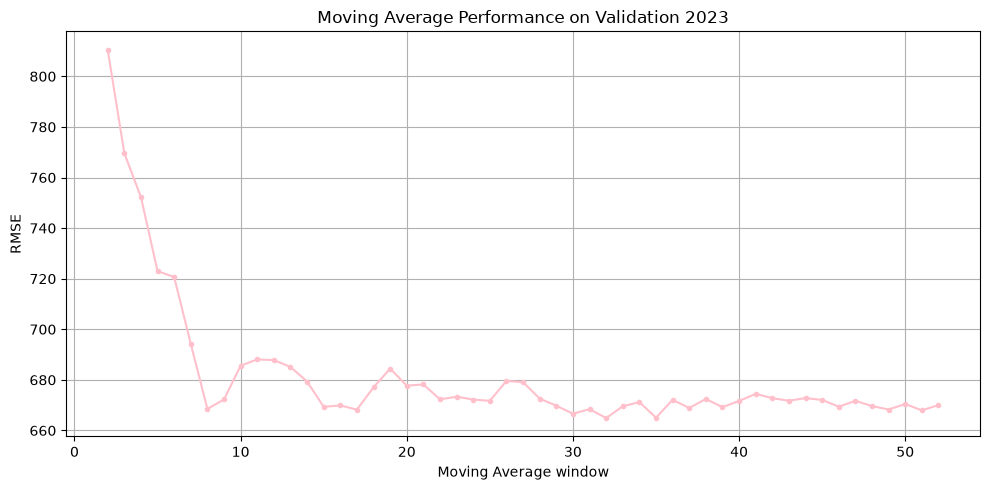

,Baseline,RMSE,MAE,sMAPE
32,MA-32,664.8961,529.1442,15.7710
35,MA-35,665.0579,530.0016,15.7950
30,MA-30,666.6232,529.9361,15.7920
51,MA-51,667.9294,540.5072,16.1118
17,MA-17,668.2397,532.7533,15.8633
49,MA-49,668.2822,537.6894,16.0255
31,MA-31,668.4336,532.7836,15.8764
8,MA-8,668.5462,528.8598,15.7305
37,MA-37,668.8950,531.8367,15.8584
39,MA-39,669.2121,529.0149,15.7707


In [ ]:
ma_df = valid_23[
    valid_23["Baseline"].str.startswith("MA-", na=False)
].copy()

ma_df["window"] = (
        ma_df["Baseline"]
        .str.replace("MA-", "", regex=False)
        .astype(int)
    )
ma_df = ma_df.sort_values("window")

plt.figure(figsize=(10, 5))
plt.plot(ma_df["window"], ma_df["RMSE"], marker="o", color="pink", markersize=3)
plt.xlabel("Moving Average window")
plt.ylabel("RMSE")
plt.title("Moving Average Performance on Validation 2023")
plt.tight_layout()
plt.grid()
plt.show()

display(ma_df.nsmallest(10, "RMSE")[["Baseline", "RMSE", "MAE", "sMAPE"]])



**Nhận xét:** Đường RMSE theo độ dài cửa sổ MA khá phẳng và ổn định trong khoảng cửa sổ trung bình đến dài (~8–51 tuần), không có hiện tượng RMSE tăng vọt đột ngột. Điều này cho thấy mô hình MA khá bền vững (robust) với lựa chọn cửa sổ trong dải này - việc chọn đúng con số 32 tuần không quá nhạy cảm vì các cửa sổ lân cận (30, 31, 35 tuần...) đều cho kết quả gần tương đương.

## 4. Seasonal Naive trên Val2023

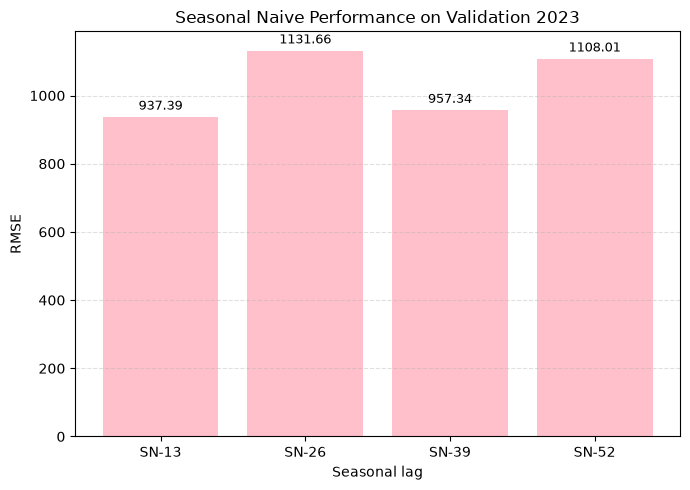

,Baseline,RMSE,MAE,sMAPE
53,SN-13,937.3900,751.3435,22.7029
54,SN-26,1131.6574,933.9473,28.2130
55,SN-39,957.3389,748.3009,22.7661
56,SN-52,1108.0130,909.6886,28.0162


In [ ]:
sn_order = ["SN-13", "SN-26", "SN-39", "SN-52"]

sn_df = valid_23[
    valid_23["Baseline"].isin(sn_order)
].copy()

sn_df["Baseline"] = pd.Categorical(
        sn_df["Baseline"],
        categories=sn_order,
        ordered=True
    )
sn_df = sn_df.sort_values("Baseline")
plt.figure(figsize=(7, 5))
bars = plt.bar(sn_df["Baseline"], sn_df["RMSE"], color="pink")
plt.bar_label(bars, labels=[f"{value:.2f}" for value in sn_df["RMSE"]], padding=3,         fontsize=9)
plt.xlabel("Seasonal lag")
plt.ylabel("RMSE")
plt.title("Seasonal Naive Performance on Validation 2023")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

display(sn_df[["Baseline", "RMSE", "MAE", "sMAPE"]])



**Nhận xét:** Toàn bộ nhóm Seasonal Naive có RMSE cao hơn đáng kể so với MA (937–1132 so với ~665–670) nghĩa là SN kém hơn khoảng 40–70%. SN-13 (937.39) và SN-39 (957.34) - lệch pha theo quý hoặc 3 quý - cho kết quả tốt hơn SN-26 và SN-52 (lệch nửa năm/1 năm) cho thấy việc lặp lại theo chu kỳ dài không nắm bắt tốt biến động doanh thu bằng chu kỳ ngắn hơn. Nhìn chung, SN chỉ đơn thuần lặp lại giá trị cùng kỳ trước đó (không làm mượt) nên nhạy với nhiễu và không tận dụng được thông tin các tuần gần nhất, do đó kém hơn nhiều so với MA.

## 5. Holt-Winters trên Val2023

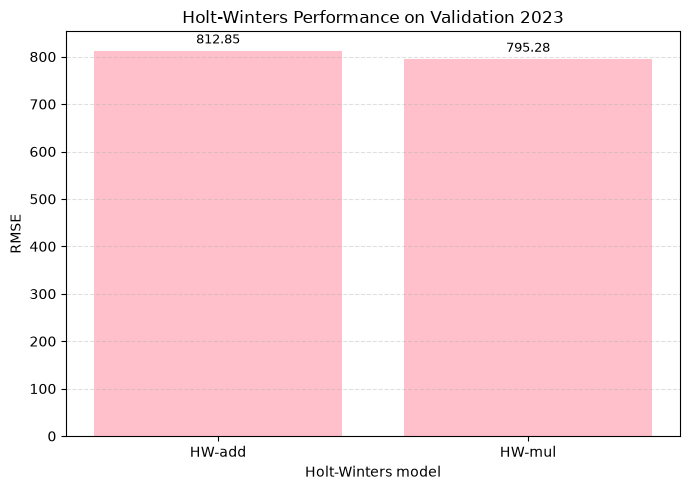

,Baseline,RMSE,MAE,sMAPE
57,HW-add,812.8482,655.1551,19.7366
58,HW-mul,795.2793,626.7886,18.9004


In [ ]:
hw_df = valid_23[
    valid_23["Baseline"].isin(["HW-add", "HW-mul"])
].copy()

plt.figure(figsize=(7, 5))
bars = plt.bar(hw_df["Baseline"], hw_df["RMSE"], color="pink")
plt.bar_label(bars, labels=[f"{value:.2f}" for value in hw_df["RMSE"]], padding=3,         fontsize=9)
plt.xlabel("Holt-Winters model")
plt.ylabel("RMSE")
plt.title("Holt-Winters Performance on Validation 2023")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

display(hw_df[["Baseline", "RMSE", "MAE", "sMAPE"]])


**Nhận xét:** Holt-Winters multiplicative (HW-mul, RMSE 795.28) hoạt động tốt hơn Additive (HW-add, RMSE 812.85), gợi ý biên độ dao động mùa vụ của doanh thu có xu hướng tỷ lệ thuận với mức nền (level) hơn là cộng thêm một hằng số - phù hợp với đặc điểm doanh thu bán lẻ thường tăng theo quy mô kinh doanh. Tuy vậy, cả hai biến thể HW vẫn kém hơn baseline MA tốt nhất khoảng 20–22%, cho thấy trên `Val2023` một phép làm mượt đơn giản (MA) lại hiệu quả hơn một mô hình có cấu trúc phức tạp hơn (HW) - có thể do dữ liệu chưa đủ dài/ổn định để HW ước lượng tốt các thành phần xu hướng và mùa vụ.

## 6. Stability check: Val2023 vs Val2024


In [ ]:
stability = summary[
    summary["split"].isin(["Val2023", "Val2024"])
].copy()

display(stability)


,split,model,RMSE,MAE,sMAPE
0,Val2023,MA-32,664.8961,529.1442,15.7710
1,Val2024,MA-32,650.5405,545.5973,16.1527


In [ ]:
stability_idx = stability.set_index("split")

rmse_23 = stability_idx.loc["Val2023", "RMSE"]
rmse_24 = stability_idx.loc["Val2024", "RMSE"]

mae_23 = stability_idx.loc["Val2023", "MAE"]
mae_24 = stability_idx.loc["Val2024", "MAE"]

smape_23 = stability_idx.loc["Val2023", "sMAPE"]
smape_24 = stability_idx.loc["Val2024", "sMAPE"]

stability_ratio = rmse_24 / rmse_23
rmse_change_pct = (rmse_24 - rmse_23) / rmse_23 * 100
mae_change_pct = (mae_24 - mae_23) / mae_23 * 100
smape_change_pct = (smape_24 - smape_23) / smape_23 * 100

print(f"RMSE Val2023 : {rmse_23:.4f}")
print(f"RMSE Val2024 : {rmse_24:.4f}")
print(f"Stability ratio (2024/2023): {stability_ratio:.3f}")
print(f"RMSE change : {rmse_change_pct:+.2f}%")
print(f"MAE change  : {mae_change_pct:+.2f}%")
print(f"sMAPE change: {smape_change_pct:+.2f}%")



RMSE Val2023 : 664.8961
RMSE Val2024 : 650.5405
Stability ratio (2024/2023): 0.978
RMSE change : -2.16%
MAE change  : +3.11%
sMAPE change: +2.42%


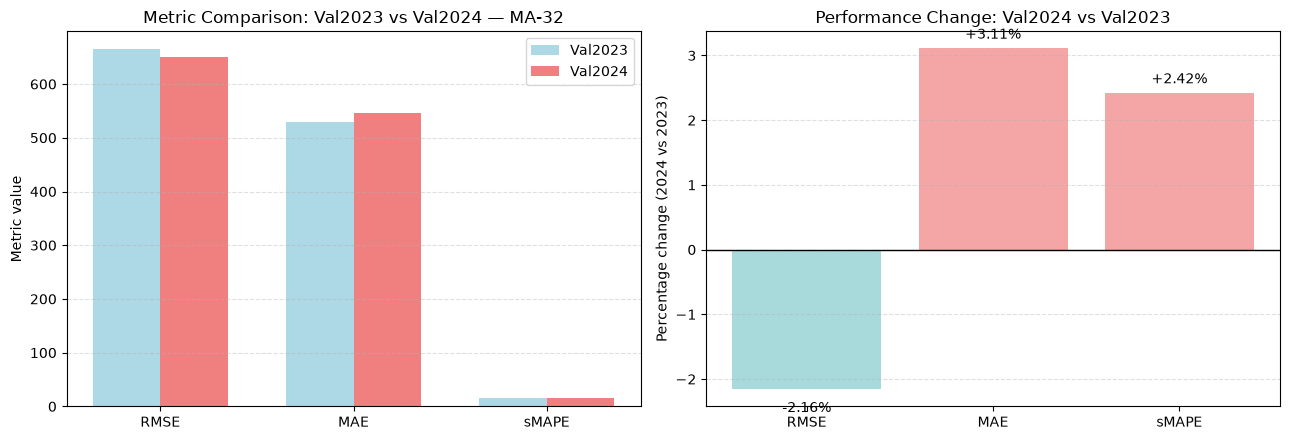

In [ ]:
metrics = ["RMSE", "MAE", "sMAPE"]
vals_23 = [rmse_23, mae_23, smape_23]
vals_24 = [rmse_24, mae_24, smape_24]
changes = [rmse_change_pct, mae_change_pct, smape_change_pct]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
#-----------------------------------------------------------------
x = np.arange(len(metrics))
width = 0.35

axes[0].bar(
    x - width / 2,
    vals_23,
    width,
    label="Val2023",
    color="lightblue"
)
axes[0].bar(
    x + width / 2,
    vals_24,
    width,
    label="Val2024",
    color="lightcoral"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].set_ylabel("Metric value")
axes[0].set_title(f"Metric Comparison: Val2023 vs Val2024 — {BEST_MODEL}")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

#-----------------------------------------------------------------

colors = ["#A8DADC" if value < 0 else "#F4A6A6" for value in changes]
axes[1].bar(metrics, changes, color=colors)
axes[1].axhline(0, color="black", linewidth=1)

for i, value in enumerate(changes):
    offset = 0.15 if value >= 0 else -0.35
    axes[1].text(
        i,
        value + offset,
        f"{value:+.2f}%",
        ha="center"
    )

axes[1].set_ylabel("Percentage change (2024 vs 2023)")
axes[1].set_title("Performance Change: Val2024 vs Val2023")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Nhận xét:** RMSE trên Val2024 giảm nhẹ so với Val2023 (-2.16%) nhưng đáng chú ý MAE và sMAPE lại tăng (+3.11% và +2.42%). Vì RMSE nhạy hơn với sai số lớn (do bình phương), RMSE giảm trong khi MAE tăng cho thấy: số lượng/độ lớn các sai số đột biến (outlier) đã giảm trên Val2024 nhưng sai số trung bình ở phần lớn các tuần thông thường lại tăng nhẹ - mô hình mượt hơn hơn nhưng kém chính xác hơn ở đa số các tuần. Nhìn chung, stability ratio 0.978 rất gần 1 nên có thể coi MA-32 khá ổn định giữa hai giai đoạn validation, đủ tin cậy để đưa vào đánh giá cuối cùng trên Test2025.

## 7. Hiệu năng xuyên suốt Val2023 → Val2024 → Test2025

Biểu đồ này chỉ dùng để quan sát khả năng tổng quát hóa theo thời gian:

- Val2023: model selection
- Val2024: stability validation
- Test2025: final evaluation

,split,model,RMSE,MAE,sMAPE
0,Val2023,MA-32,664.8961,529.1442,15.7710
1,Val2024,MA-32,650.5405,545.5973,16.1527
2,Test2025,MA-32,764.7267,589.5561,17.6180


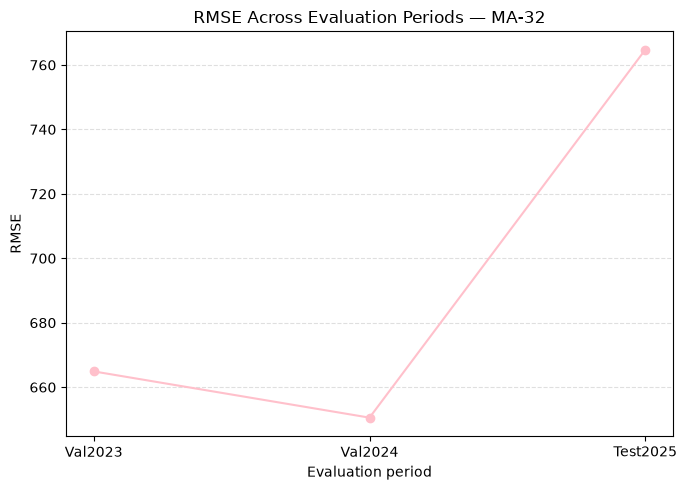

In [ ]:
display(summary)

plt.figure(figsize=(7, 5))
plt.plot(summary["split"], summary["RMSE"], marker="o", color="pink")
plt.xlabel("Evaluation period")
plt.ylabel("RMSE")
plt.title(f"RMSE Across Evaluation Periods — {BEST_MODEL}")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [ ]:
metric_table = summary[
    ["split", "model", "RMSE", "MAE", "sMAPE"]
].copy()

display(metric_table)


,split,model,RMSE,MAE,sMAPE
0,Val2023,MA-32,664.8961,529.1442,15.7710
1,Val2024,MA-32,650.5405,545.5973,16.1527
2,Test2025,MA-32,764.7267,589.5561,17.6180


**Nhận xét:** So với Val2024 (RMSE 650.54), RMSE trên Test2025 tăng mạnh lên 764.73 (+17.6%), mức tăng lớn hơn nhiều so với biến động giữa Val2023 → Val2024 (chỉ -2.16%). MAE và sMAPE trên Test2025 cũng cao hơn rõ rệt (589.56 và 17.62% so với 545.60 và 16.15% của Val2024). Điều này cho thấy MA-32 tổng quát hóa sang Test2025 kém hơn so với giữa hai tập validation, có thể do đặc điểm dữ liệu 2025 đã thay đổi (dịch chuyển phân phối, cú sốc thị trường...) hoặc do bản chất đơn giản của baseline MA không thích ứng được khi xu hướng/mùa vụ thay đổi. 

## 8. Actual và Predicted của MA-32 trên tập Test 2025

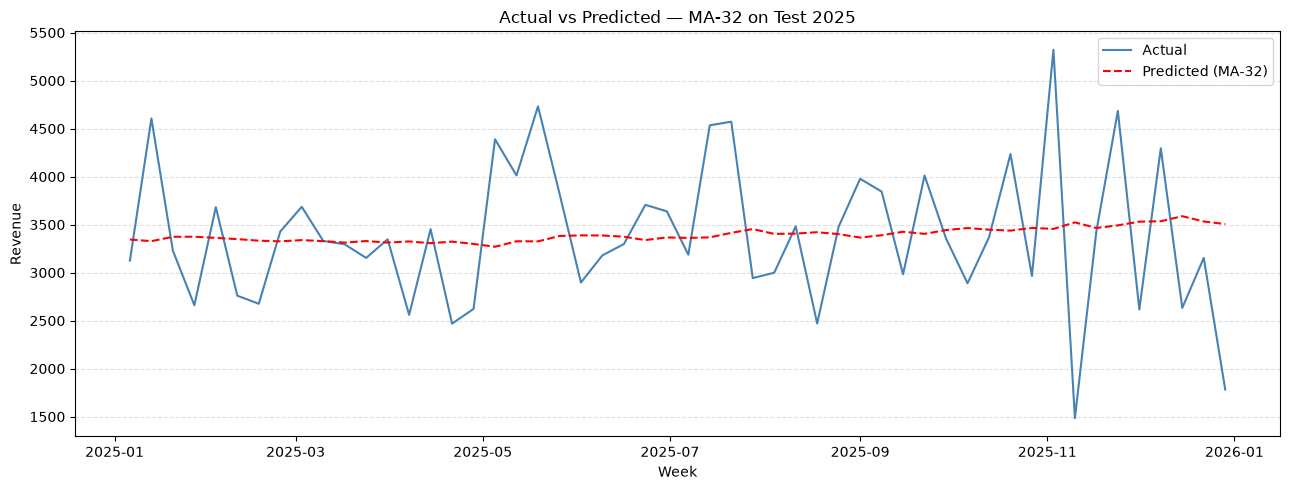

In [ ]:
plt.figure(figsize=(13, 5))

plt.plot(
    prediction_check["week_start"],
    prediction_check["actual"],
    label="Actual",
    color="steelblue"
)

plt.plot(
    prediction_check["week_start"],
    prediction_check["predicted"],
    label=f"Predicted ({BEST_MODEL})",
    linestyle="--",
    color="red"
)

plt.xlabel("Week")
plt.ylabel("Revenue")
plt.title(f"Actual vs Predicted — {BEST_MODEL} on Test 2025")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


**Nhận xét:** đường Predicted (MA-32) bám khá sát đường Actual về xu hướng chung, đúng như kỳ vọng của một mô hình trung bình trượt - làm mượt biến động ngắn hạn và theo kịp xu hướng dài hạn. Tuy nhiên do bản chất "trễ" (lagging) của MA, mô hình có thể phản ứng chậm hơn tại các thời điểm doanh thu biến động đột ngột (ví dụ các đợt cao điểm mùa vụ hoặc khuyến mãi) dẫn đến sai số cục bộ lớn hơn ở những tuần này.

## 9. Forecast Error trên Test2025

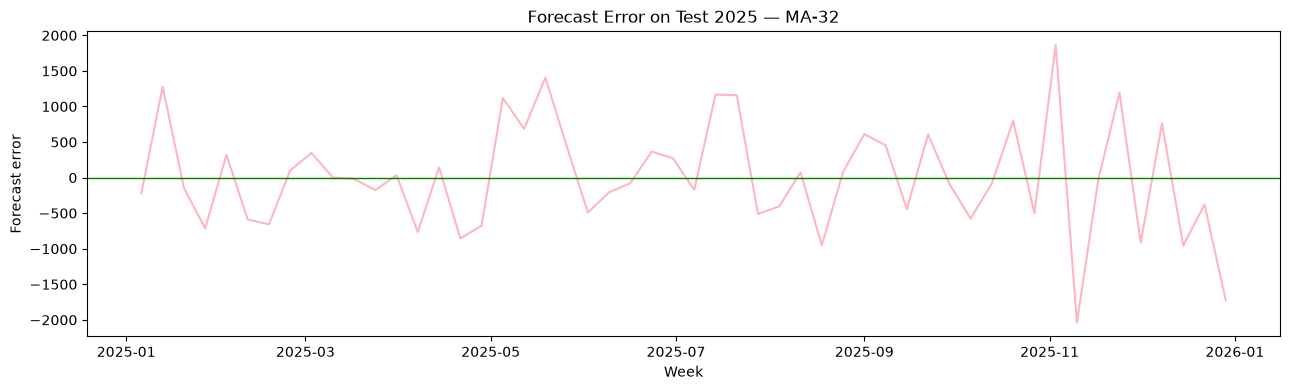

Mean error: -1.3087
Max absolute error: 2038.5878


In [ ]:
test_plot = prediction_check.copy()
test_plot["error"] = (test_plot["actual"]- test_plot["predicted"])

plt.figure(figsize=(13, 4))
plt.plot(
    test_plot["week_start"],
    test_plot["error"],
    label="Forecast error",
    color="lightpink"
)
plt.axhline(0, linewidth=1, color="green")
plt.xlabel("Week")
plt.ylabel("Forecast error")
plt.title(f"Forecast Error on Test 2025 — {BEST_MODEL}")
plt.tight_layout()
plt.show()

print("Mean error:", round(test_plot["error"].mean(), 4))
print("Max absolute error:", round(test_plot["error"].abs().max(), 4))


**Nhận xét:** Sai số trung bình (mean error) trên Test2025 chỉ -1.31, gần như bằng 0, cho thấy mô hình không bị lệch (bias) hệ thống - không dự báo thiên cao hay thiên thấp một cách nhất quán. Tuy nhiên, sai số tuyệt đối lớn nhất lên tới 2038.59 - gấp khoảng 3 lần RMSE (764.73) - cho thấy tồn tại (các) tuần có sai số đột biến rất lớn, nhiều khả năng tương ứng với các sự kiện bất thường (lễ Tết, khuyến mãi lớn, sự kiện ngoài dự kiến...) mà một baseline MA đơn giản không thể nắm bắt. Đây là dấu hiệu cho thấy dù trung bình ổn, mô hình vẫn có rủi ro sai số lớn cục bộ cần được các mô hình phức tạp hơn xử lý tốt hơn.



## 10. Kết luận 

- **Baseline được chọn:** MA-32 (trung bình trượt 32 tuần) dựa trên RMSE thấp nhất trên Val2023.
- **Xếp hạng nhóm mô hình trên Val2023 (tốt → kém theo RMSE):** `MA < HW-mul < HW-add < SN`. Nhóm MA vượt trội và khá bền vững qua nhiều lựa chọn cửa sổ; SN là nhóm yếu nhất.
- **Độ ổn định Val2023 → Val2024:** khá tốt (stability ratio ≈ 0.98) dù MAE/sMAPE tăng nhẹ.
- **Tổng quát hóa sang Test2025:** hiệu năng giảm rõ rệt với RMSE tăng 17.6% so với Val2024. Kết quả này cho thấy mô hình MA-32 vẫn còn hạn chế khi xử lý các biến động mạnh và có thể được cải thiện bằng các mô hình phức tạp hơn, đặc biệt tại các tuần có sai số tuyệt đối lớn lên đến khoảng 2039.